Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...       

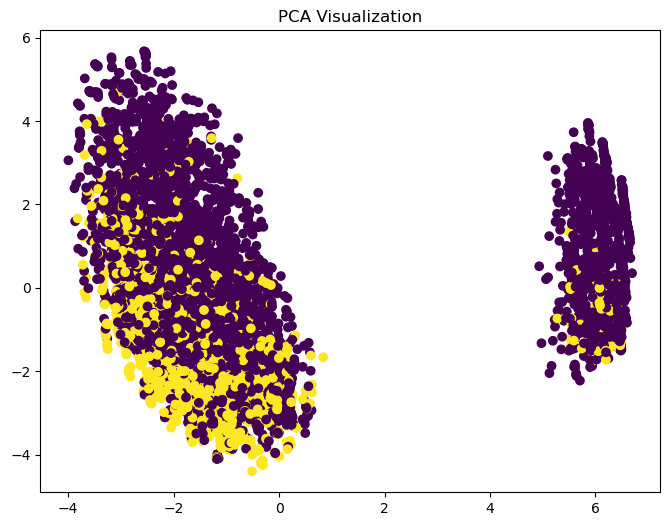

                     Accuracy  Precision    Recall  F1-Score       AUC
Logistic Regression  0.779565   0.646512  0.469595  0.544031  0.798085
Decision Tree        0.774834   0.627193  0.483108  0.545802  0.687689
Naive Bayes          0.287606   0.269889  0.905405  0.415826  0.476356
Random Forest        0.789026   0.701657  0.429054  0.532495  0.831643
   Logistic Regression  Decision Tree  Naive Bayes  Random Forest
0             0.787793       0.777147     0.278921       0.800568
1             0.794180       0.764372     0.278211       0.792761
2             0.763662       0.763662     0.288857       0.775018
3             0.781250       0.757102     0.274148       0.798295
4             0.786932       0.768466     0.275568       0.797585
Best parameters for Logistic Regression: {'C': 0.1, 'max_iter': 100}
Best cross-validation score for Logistic Regression: 0.7819472616632861
                             feature  importance
1                             tenure    0.122504
2         

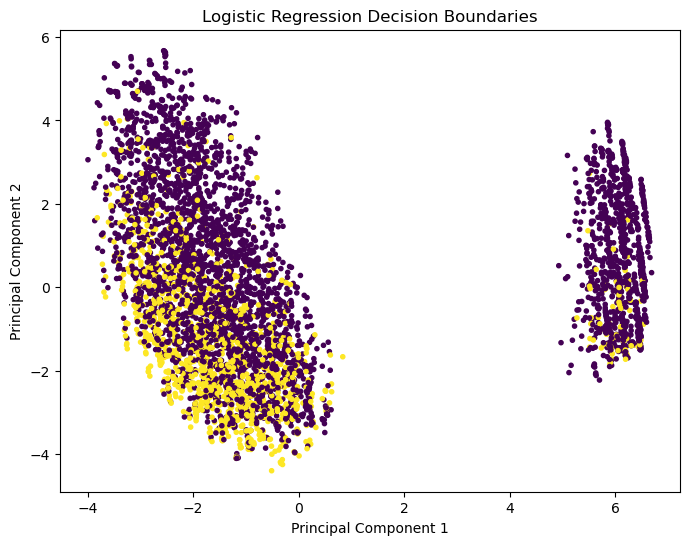

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Load and preprocess your data
data = pd.read_csv(r"C:\Users\mihir\Downloads\archive (2)\WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(data.columns)
print(data.head())

# Encode 'Churn' column as binary
data['Churn'] = data['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Drop 'customerID' column explicitly (after confirming it exists)
if 'customerID' in data.columns:
    data = data.drop(['customerID'], axis=1)

# Preprocess the data (Handle missing values, encode categorical features, etc.)
data.fillna(method='ffill', inplace=True)
data = pd.get_dummies(data, drop_first=True)

# Define features and target
X = data.drop(['Churn'], axis=1)  # Use 'Churn' column as the target
y = data['Churn']  # Target variable

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split data into training, validation, and test sets (70% train, 15% validation, 15% test)
X_train, X_temp, y_train, y_temp = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Apply PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

# Visualize PCA results
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='viridis')
plt.title('PCA Visualization')
plt.show()

# Train multiple classifiers

# Logistic Regression
log_reg = LogisticRegression(max_iter=200)
log_reg.fit(X_train, y_train)
log_reg_predictions = log_reg.predict(X_test)

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_predictions = dt.predict(X_test)

# Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_predictions = nb.predict(X_test)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_predictions = rf.predict(X_test)

# Evaluate models
models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dt,
    "Naive Bayes": nb,
    "Random Forest": rf
}

# Store results in a DataFrame
results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    results.append([accuracy, precision, recall, f1, auc])

results_df = pd.DataFrame(results, columns=["Accuracy", "Precision", "Recall", "F1-Score", "AUC"], index=models.keys())
print(results_df)

# Perform Cross-Validation
cv_scores = {}
for model_name, model in models.items():
    cv_scores[model_name] = cross_val_score(model, X_scaled, y, cv=5, scoring='accuracy')

cv_scores_df = pd.DataFrame(cv_scores)
print(cv_scores_df)

param_grid = {'C': [0.1, 1, 10, 100], 'max_iter': [100, 200, 300]}
grid_search = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
print(f'Best parameters for Logistic Regression: {grid_search.best_params_}')
print(f'Best cross-validation score for Logistic Regression: {grid_search.best_score_}')

importances = rf.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)
print(feature_importance_df)

bagging_lr = BaggingClassifier(base_estimator=log_reg, n_estimators=50, random_state=42)
bagging_lr.fit(X_train, y_train)
bagging_lr_predictions = bagging_lr.predict(X_test)

adaboost_lr = AdaBoostClassifier(base_estimator=log_reg, n_estimators=50, random_state=42)
adaboost_lr.fit(X_train, y_train)
adaboost_lr_predictions = adaboost_lr.predict(X_test)

ensemble_models = {
    "Logistic Regression (Bagging)": bagging_lr,
    "Logistic Regression (AdaBoost)": adaboost_lr
}

ensemble_results = []

for model_name, model in ensemble_models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    ensemble_results.append([accuracy, precision, recall, f1, auc])

ensemble_results_df = pd.DataFrame(ensemble_results, columns=["Accuracy", "Precision", "Recall", "F1-Score", "AUC"], index=ensemble_models.keys())
print(ensemble_results_df)

log_reg.fit(X_pca, y_train)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='viridis', marker='.')
plt.title('Logistic Regression Decision Boundaries')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()
